# Simulated Data

In [ ]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [1]:
# load Merfish mouse brain 33 data
in_ = '/hpc/group/hickeylab/fl135/pkl_data/'

i = 23
file_path = in_ + 'merfish_mouse_brain_slice' + str(i) + '.h5ad'
ad = sc.read(file_path)
ad.obs['original_clusters']=ad.obs['spa_cluster'].astype('category')
ad.obsm['spatial'] = ad.obsm['spatial'].to_numpy()[:, :2]
ad

NameError: name 'sc' is not defined

In [ ]:
file_path = in_ + 'merfish_mouse_brain_slice' + str(i-1) + '.h5ad'
ad_target = sc.read(file_path)
ad_target.obs['original_clusters']=ad_target.obs['spa_cluster'].astype('category')
ad_target.obsm['spatial'] = ad_target.obsm['spatial'].to_numpy()[:, :2]
ad_target

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

sc.pl.spatial(ad, color='original_clusters', spot_size=30, ax=axes[0], show=False)
sc.pl.spatial(ad_target, color='original_clusters', spot_size=30, ax=axes[1], show=False)
plt.show()

In [2]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = -spatial_coords_target[:, 1]
y_target = -spatial_coords_target[:, 0]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=20,blur=1.5, draw=False)

NameError: name 'ad_target' is not defined

In [3]:
spatial_coords = ad.obsm['spatial']
x = spatial_coords[:, 0]
y = -spatial_coords[:, 1]

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I = STalign.rasterize(x,y,dx=20,blur=1.5,draw=False)

NameError: name 'ad' is not defined

In [4]:
x_target = x_target -1000
y_target = y_target +600

x = x -1800
y = y -2600

NameError: name 'x_target' is not defined

In [5]:
# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I = STalign.rasterize(x,y,dx=20,blur=1.5,draw=False)
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=20,blur=1.5,draw=False)

NameError: name 'STalign' is not defined

In [6]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

NameError: name 'STalign' is not defined

In [7]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            # 'niter':10000,
            # 'pointsI':pointsI,
            # 'pointsJ':pointsJ,
            # 'L':L,'T':T,
            'niter':8000,
            'device':device,
            'epV': 20,
            'sigmaA': 0.5, #standard deviation of artifact intensities
            'sigmaB': 0.5, #standard deviation of background intensities
            'sigmaM': 0.5, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

NameError: name 'torch' is not defined

In [15]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']


In [16]:
# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, np.stack([y, x], 1).astype(np.float64))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

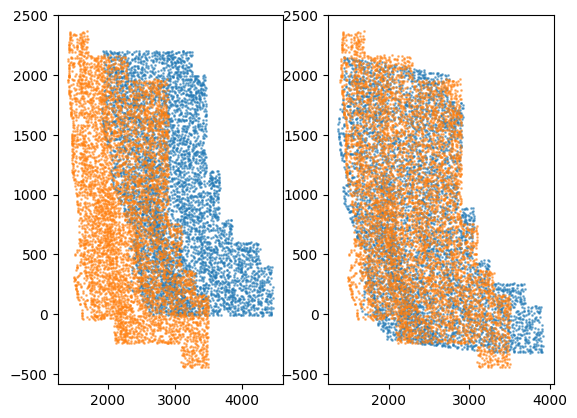

In [17]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

In [18]:
from sklearn.metrics import pairwise

f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)
alignment = pairwise.euclidean_distances(f1, f2)
alignment = np.exp(-alignment)

alignment_df = pd.DataFrame(alignment)


In [19]:
# Save as .pkl
alignment_df.to_pickle("22_23_AlignmentPi.pkl")

## LAA

In [20]:
def cal_layer_based_alignment_result_mHypothalamus(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    #l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    ir = 0
    max_smallerThan0 = []
    sum_smallerThan0 = []
    min_smallerThan0 = []

    for i, elem in enumerate(alignment):
        #if np.sum(elem)>0:
        if np.max(elem) - np.min(elem) != 0:
            if labels[i] == labels[elem.argmax() + alignment.shape[0]]:
                cnt0 += 1
        else:
            ir += 1
            max_smallerThan0.append(np.max(elem))
            sum_smallerThan0.append(np.sum(elem))
            min_smallerThan0.append(np.min(elem))
    print("the number of sum alignment equals 0:", str(cnt0))
    if len(sum_smallerThan0)>0:
        print("sum in sum alignment equals 0 is between", np.min(sum_smallerThan0), np.max(sum_smallerThan0))
        print("max in sum alignment equals 0 is between", np.min(max_smallerThan0), np.max(max_smallerThan0))
        print("min in sum alignment equals 0 is between", np.min(min_smallerThan0), np.max(min_smallerThan0))
    res.extend([cnt0])
    return res

In [21]:
res = cal_layer_based_alignment_result_mHypothalamus(alignment, ad, ad_target)
res[0]/len(ad.obs['original_clusters'])

the number of sum alignment equals 0: 1006


0.1871627906976744

In [83]:
alignment.shape

(3611, 3596)

## ARI

In [22]:
from sklearn.metrics import adjusted_rand_score


def compute_alignment_ari(sliceA, sliceB, pi):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [23]:
ari = compute_alignment_ari(ad_target, ad, alignment)
ari

0.49441572284446383

## 3D

In [49]:
unique_clusters = ad.obs['original_clusters']
for jjj in range(1, 2):
    unique_clusters = sorted(np.unique(
        np.concatenate([
            unique_clusters,
            ad.obs['original_clusters']
        ])
    ))

cmap = []
if len(unique_clusters) <= 10: # when no. of layers <=10
    for e in plt.get_cmap('tab10').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
else: # when 10< no. of layers <=40
    for e in plt.get_cmap('tab20').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
    for e in plt.get_cmap('tab20b').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))

# Create the dictionary with the combined clusters
c_dict = dict(zip(unique_clusters, cmap))
c_dict

In [24]:
c_dict = {
    1: '#1f77b4',
    2: '#ff7f0e',
    3: '#2ca02c',
    4: '#d62728',
    5: '#9467bd',
    6: '#8c564b',
    0: '#e377c2'
    }

In [98]:
# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, np.stack([y, x], 1))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

In [25]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,100061139265760175796402115278970187488,4
1,100106598365688643089698668757228303964,0
2,100111985783255514946207722946273187017,4
3,100123806067060025203221776241023194026,4
4,100129977784630015405675009906177293164,1


In [26]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 23
results1['slice'] = 'slice23'
results1

,index,original_clusters,X,Y,Z,slice
0,100061139265760175796402115278970187488,4,3417.309229,20.244687,23,slice23
1,100106598365688643089698668757228303964,0,2899.965606,1413.429359,23,slice23
2,100111985783255514946207722946273187017,4,3127.491779,200.836027,23,slice23
3,100123806067060025203221776241023194026,4,2455.100362,1982.319684,23,slice23
4,100129977784630015405675009906177293164,1,1496.999386,1031.157969,23,slice23
...,...,...,...,...,...,...
5370,99666121660929551933508596945690554474,5,3363.343950,-199.783330,23,slice23
5371,9973915450998753832998867807069003635,3,1816.687022,1129.933619,23,slice23
5372,99805378775772322211205131570332947428,2,2101.737641,1195.056683,23,slice23
5373,99817592108537455108936770379707219711,0,2849.095415,1660.556932,23,slice23


In [27]:
results1['celltype_colors'] = results1['original_clusters'].replace(c_dict)
results1

,index,original_clusters,X,Y,Z,slice,celltype_colors
0,100061139265760175796402115278970187488,4,3417.309229,20.244687,23,slice23,#d62728
1,100106598365688643089698668757228303964,0,2899.965606,1413.429359,23,slice23,#e377c2
2,100111985783255514946207722946273187017,4,3127.491779,200.836027,23,slice23,#d62728
3,100123806067060025203221776241023194026,4,2455.100362,1982.319684,23,slice23,#d62728
4,100129977784630015405675009906177293164,1,1496.999386,1031.157969,23,slice23,#1f77b4
...,...,...,...,...,...,...,...
5370,99666121660929551933508596945690554474,5,3363.343950,-199.783330,23,slice23,#9467bd
5371,9973915450998753832998867807069003635,3,1816.687022,1129.933619,23,slice23,#2ca02c
5372,99805378775772322211205131570332947428,2,2101.737641,1195.056683,23,slice23,#ff7f0e
5373,99817592108537455108936770379707219711,0,2849.095415,1660.556932,23,slice23,#e377c2


In [29]:
results1.to_csv("23.csv", index=False)